# Practical 6 — Logistic Regression

**Aim:** Classify breast tumours (benign / malignant) with logistic regression and evaluate with train/test split and
k-fold CV. Report Accuracy, TP, TN, FP, FN, Error, Recall, Specificity, F1 and AUC.

**Dataset:** Breast Cancer Wisconsin (Diagnostic) – UCI repository, bundled with scikit-learn.

**Idea:** Despite its name it is a *classifier*.
1. Linear score  z = β₀ + β₁x₁ + … + β_p x_p
2. Squash into a probability with the **sigmoid** σ(z) = 1 / (1 + e⁻ᶻ)
3. Predict class 1 if σ(z) ≥ 0.5 (threshold).
Coefficients are learned by minimising the **log-loss** −mean[y·log p + (1−y)·log(1−p)] (maximum likelihood).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.precision", 4)

## Evaluation helpers (shared by all classification practicals)
The syllabus asks us to report **Accuracy, TP, TN, FP, FN, Error, Recall, Specificity, F1-score and AUC**.
* `classification_metrics` – builds the confusion matrix `[[TN, FP], [FN, TP]]` and derives every metric from it
  (formulas are in the docstring).
* `kfold_evaluate` – manual **stratified k-fold cross-validation**: for every fold it clones the model, trains on
  k-1 folds, tests on the held-out fold and records all metrics, so you can see each intermediate result.

In [2]:
from sklearn.base import clone
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.model_selection import StratifiedKFold


def classification_metrics(y_true, y_pred, y_score=None):
    """Return all metrics required by the syllabus for a BINARY problem (positive class = 1).

    Accuracy    = (TP+TN)/(TP+TN+FP+FN)      Error       = 1 - Accuracy
    Recall      = TP/(TP+FN)  (sensitivity)  Specificity = TN/(TN+FP)
    Precision   = TP/(TP+FP)                 F1          = 2*P*R/(P+R)
    AUC         = area under the ROC curve (needs a continuous score, not the hard label)
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    auc = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    return pd.Series({"TP": tp, "TN": tn, "FP": fp, "FN": fn, "Accuracy": accuracy,
                      "Error": 1 - accuracy, "Recall": recall, "Specificity": specificity,
                      "Precision": precision, "F1": f1, "AUC": auc})


def get_score(model, X):
    """Continuous score used for AUC: P(class=1) if available, otherwise the SVM-style decision value."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def kfold_evaluate(model, X, y, k=5, seed=42):
    """Stratified k-fold CV. Returns (per-fold table, mean/std summary)."""
    X, y = np.asarray(X), np.asarray(y)
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    rows = []
    for fold, (tr, te) in enumerate(skf.split(X, y), start=1):
        m = clone(model).fit(X[tr], y[tr])                 # fresh, untrained copy each fold
        r = classification_metrics(y[te], m.predict(X[te]), get_score(m, X[te]))
        r.name = f"Fold {fold}"
        rows.append(r)
        print(f"Fold {fold}: train={len(tr)}, test={len(te)}, accuracy={r['Accuracy']:.4f}, AUC={r['AUC']:.4f}")
    folds = pd.DataFrame(rows)
    return folds, pd.DataFrame({"mean": folds.mean(), "std": folds.std()})


def plot_cm_roc(model, X_test, y_test, title=""):
    """Confusion matrix + ROC curve side by side."""
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax[0], cmap="Blues",
                                          display_labels=["Benign (0)", "Malignant (1)"])
    ax[0].set_title(f"Confusion matrix {title}")
    fpr, tpr, _ = roc_curve(y_test, get_score(model, X_test))
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_test, get_score(model, X_test)):.3f}")
    ax[1].plot([0, 1], [0, 1], "k--", label="Chance")
    ax[1].set(xlabel="False Positive Rate (1 - Specificity)", ylabel="True Positive Rate (Recall)",
              title=f"ROC curve {title}")
    ax[1].legend(); plt.tight_layout(); plt.show()

## Step 1 — Load and inspect the data

In [3]:
data = load_breast_cancer(as_frame=True)
X_df = data.data                                  # 30 numeric features
y_s = (data.target == 0).astype(int)              # flip so that 1 = MALIGNANT (the "positive" class), 0 = benign
df = X_df.assign(target=y_s)

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("\nClass balance (1 = malignant):")
print(y_s.value_counts().rename({0: "benign", 1: "malignant"}))
df.head()

Shape: (569, 31)
Missing values: 0

Class balance (1 = malignant):
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,1
1,20.57,17.77,132.90,1326.0,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,1
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,1
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,1
4,20.29,14.34,135.10,1297.0,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,1


## Step 2 — Train / test split and feature scaling
Features have very different ranges (e.g. area ≈ 500–2500, smoothness ≈ 0.1). Gradient-based solvers converge faster and
regularisation is fair when features are standardised, so we apply `StandardScaler` (fit on the training set only).

In [4]:
X, y = X_df.values, y_s.values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)
print("Train:", Xs_train.shape, "Test:", Xs_test.shape)

Train: (455, 30) Test: (114, 30)


## Step 3 — The sigmoid function

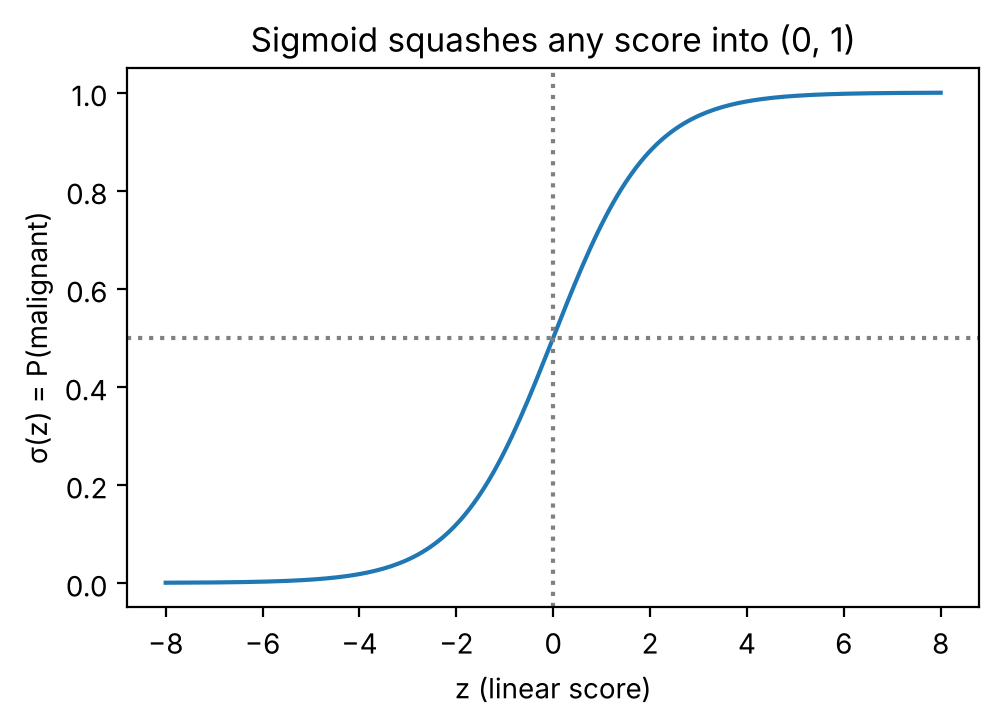

σ(-4)=0.0180  σ(0)=0.5000  σ(4)=0.9820


In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

zs = np.linspace(-8, 8, 200)
plt.figure(figsize=(5.5, 3.5))
plt.plot(zs, sigmoid(zs)); plt.axhline(0.5, color="gray", ls=":"); plt.axvline(0, color="gray", ls=":")
plt.xlabel("z (linear score)"); plt.ylabel("σ(z) = P(malignant)"); plt.title("Sigmoid squashes any score into (0, 1)")
plt.show()
print("σ(-4)=%.4f  σ(0)=%.4f  σ(4)=%.4f" % (sigmoid(-4), sigmoid(0), sigmoid(4)))

## Step 4 — Training from scratch with gradient descent
What `fit()` does, in plain NumPy (sklearn uses a faster solver, L-BFGS, but the objective is the same).
scikit-learn's default is **L2-regularised** logistic regression (`C = 1`; smaller C = stronger penalty), whose per-sample
objective is  mean log-loss + ‖w‖² / (2·C·n). We minimise exactly that:
1. Initialise w = 0, b = 0.
2. **Forward:** z = Xw + b, p = σ(z).
3. **Loss:** log-loss of p vs the true labels (+ the L2 penalty on w; the bias is not penalised).
4. **Gradient:** ∂L/∂w = Xᵀ(p − y)/n + w/(C·n),  ∂L/∂b = mean(p − y).
5. **Update:** w ← w − η·∂L/∂w, b ← b − η·∂L/∂b (η = learning rate). Repeat.

iter    0 | loss = 0.6931 | train accuracy = 0.3736
iter    1 | loss = 0.2379 | train accuracy = 0.9319
iter    2 | loss = 0.2026 | train accuracy = 0.9429
iter   10 | loss = 0.1261 | train accuracy = 0.9714
iter   50 | loss = 0.0863 | train accuracy = 0.9802
iter  100 | loss = 0.0780 | train accuracy = 0.9824


iter  500 | loss = 0.0695 | train accuracy = 0.9890


iter 1000 | loss = 0.0688 | train accuracy = 0.9890


iter 5000 | loss = 0.0687 | train accuracy = 0.9868


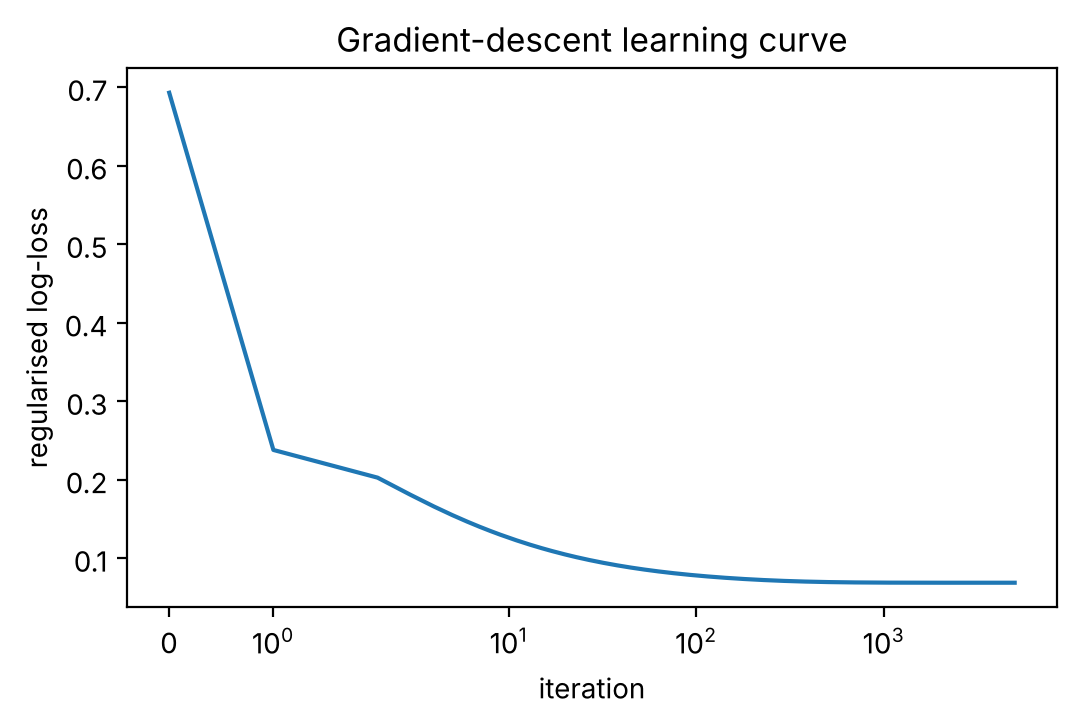

In [6]:
def fit_logistic_gd(X, y, C=1.0, lr=0.5, n_iter=5000, verbose=True):
    n, p = X.shape
    w, b = np.zeros(p), 0.0
    history = []
    for i in range(n_iter + 1):
        prob = sigmoid(X @ w + b)                                                     # step 2
        loss = -np.mean(y * np.log(prob + 1e-12) + (1 - y) * np.log(1 - prob + 1e-12)) + w @ w / (2 * C * n)   # step 3
        history.append(loss)
        if verbose and i in (0, 1, 2, 10, 50, 100, 500, 1000, n_iter):
            print(f"iter {i:4d} | loss = {loss:.4f} | train accuracy = {((prob >= .5) == y).mean():.4f}")
        grad_w = X.T @ (prob - y) / n + w / (C * n)                                   # step 4
        grad_b = np.mean(prob - y)
        w -= lr * grad_w; b -= lr * grad_b                                            # step 5
    return w, b, history

w_gd, b_gd, hist = fit_logistic_gd(Xs_train, y_train)
plt.figure(figsize=(6, 3.5)); plt.plot(hist); plt.xscale("symlog"); plt.xlabel("iteration"); plt.ylabel("regularised log-loss")
plt.title("Gradient-descent learning curve"); plt.show()

## Step 5 — scikit-learn `LogisticRegression` and comparison
Same data, same objective (`C = 1`) – the two solutions should agree.

In [7]:
model = LogisticRegression(C=1.0, max_iter=10000).fit(Xs_train, y_train)
print("Test accuracy – scratch GD  :", round(((sigmoid(Xs_test @ w_gd + b_gd) >= 0.5) == y_test).mean(), 4))
print("Test accuracy – sklearn     :", round(model.score(Xs_test, y_test), 4))
print("Largest |coefficient difference| GD vs sklearn: %.4f" % np.abs(w_gd - model.coef_[0]).max())
print("Correlation of the 30 coefficients: %.5f" % np.corrcoef(w_gd, model.coef_[0])[0, 1])
print("Intercept GD: %.4f | sklearn: %.4f" % (b_gd, model.intercept_[0]))
print("Same solution (to 2 decimals):", np.allclose(w_gd, model.coef_[0], atol=0.02))

Test accuracy – scratch GD  : 0.9649
Test accuracy – sklearn     : 0.9649
Largest |coefficient difference| GD vs sklearn: 0.0094
Correlation of the 30 coefficients: 0.99998
Intercept GD: -0.2413 | sklearn: -0.2430
Same solution (to 2 decimals): True


## Step 6 — What does `predict()` / `predict_proba()` do? (one sample by hand)

In [8]:
x0 = Xs_test[0]
z = model.intercept_[0] + x0 @ model.coef_[0]
p = sigmoid(z)
print("True label of test sample 0 :", y_test[0])
print(f"Step 6.1  z = β0 + Σ βj·xj           = {z:.4f}")
print(f"Step 6.2  p = σ(z) = 1/(1+e^-z)      = {p:.6f}")
print(f"Step 6.3  p ≥ 0.5 ?  → predicted class = {int(p >= 0.5)}")
print("sklearn predict_proba:", model.predict_proba(x0.reshape(1, -1))[0].round(6), "| predict:", model.predict(x0.reshape(1, -1))[0])

True label of test sample 0 : 0
Step 6.1  z = β0 + Σ βj·xj           = -7.9164
Step 6.2  p = σ(z) = 1/(1+e^-z)      = 0.000365
Step 6.3  p ≥ 0.5 ?  → predicted class = 0
sklearn predict_proba: [9.99635e-01 3.65000e-04] | predict: 0


## Step 7 — Interpreting the coefficients
A coefficient β is the change in **log-odds** for +1 standard deviation of that feature; **e^β is the odds ratio**.

In [9]:
coef = pd.DataFrame({"coef": model.coef_[0], "odds_ratio": np.exp(model.coef_[0])}, index=X_df.columns)
display(coef.reindex(coef["coef"].abs().sort_values(ascending=False).index).head(8))

,coef,odds_ratio
worst texture,1.4341,4.1958
radius error,1.2333,3.4326
worst symmetry,1.0613,2.8900
mean concave points,0.9528,2.5930
worst concavity,0.9114,2.4878
area error,0.9090,2.4819
compactness error,-0.9069,0.4038
worst area,0.9005,2.4608


## Step 8 — Evaluation on the hold-out test set

TP             39.0000
TN             71.0000
FP              1.0000
FN              3.0000
Accuracy        0.9649
Error           0.0351
Recall          0.9286
Specificity     0.9861
Precision       0.9750
F1              0.9512
AUC             0.9960



              precision    recall  f1-score   support

      benign       0.96      0.99      0.97        72
   malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



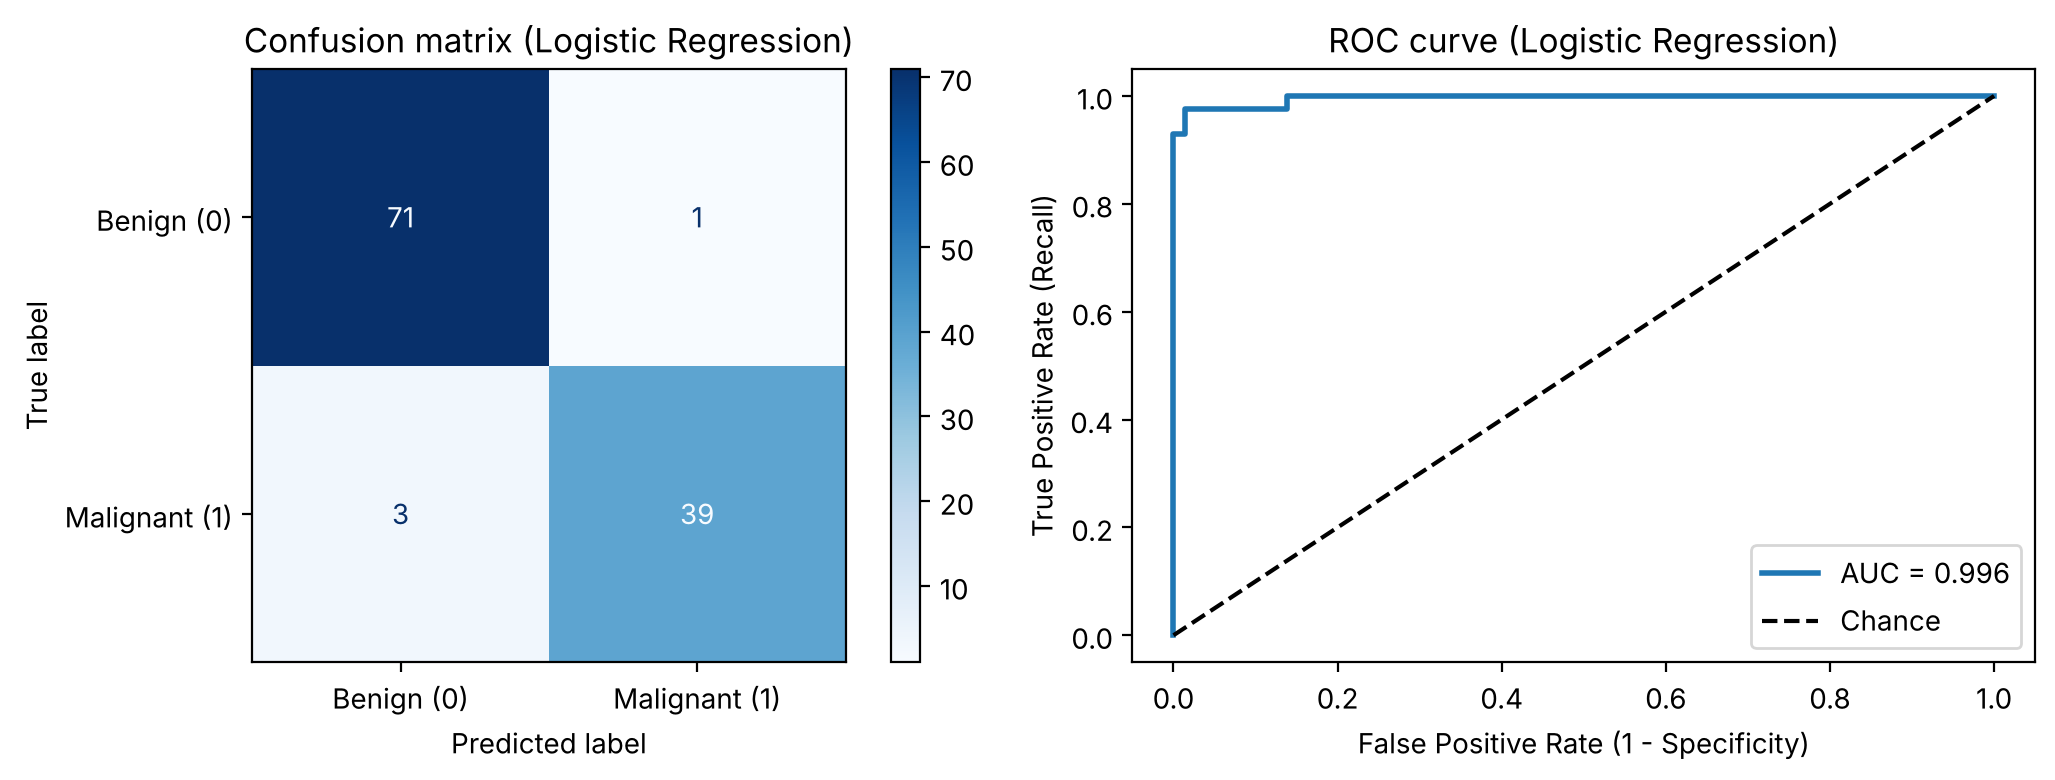

In [10]:
y_pred = model.predict(Xs_test)
test_m = classification_metrics(y_test, y_pred, model.predict_proba(Xs_test)[:, 1])
print(test_m.round(4).to_string())
print()
print(classification_report(y_test, y_pred, target_names=["benign", "malignant"]))
plot_cm_roc(model, Xs_test, y_test, title="(Logistic Regression)")

### Effect of the decision threshold
0.5 is only a default. Lowering it catches more malignant tumours (↑ Recall) at the price of more false alarms (↓ Specificity).

In [11]:
proba = model.predict_proba(Xs_test)[:, 1]
rows = []
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    m = classification_metrics(y_test, (proba >= t).astype(int), proba)
    rows.append({"threshold": t, "TP": m["TP"], "FP": m["FP"], "FN": m["FN"], "TN": m["TN"],
                 "Recall": m["Recall"], "Specificity": m["Specificity"], "Accuracy": m["Accuracy"]})
display(pd.DataFrame(rows).set_index("threshold").round(4))

,TP,FP,FN,TN,Recall,Specificity,Accuracy
threshold,,,,,,,
0.1,41.0,5.0,1.0,67.0,0.9762,0.9306,0.9474
0.3,41.0,1.0,1.0,71.0,0.9762,0.9861,0.9825
0.5,39.0,1.0,3.0,71.0,0.9286,0.9861,0.9649
0.7,38.0,0.0,4.0,72.0,0.9048,1.0000,0.9649
0.9,33.0,0.0,9.0,72.0,0.7857,1.0000,0.9211


## Step 9 — k-fold cross-validation (k = 5)
The scaler is inside the pipeline so it is re-fitted on the training folds only (no information leaks from the held-out fold).

In [12]:
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
folds, summary = kfold_evaluate(pipe, X, y, k=5)
print()
display(folds.round(4)); display(summary.round(4))

Fold 1: train=455, test=114, accuracy=0.9737, AUC=0.9951
Fold 2: train=455, test=114, accuracy=0.9474, AUC=0.9977
Fold 3: train=455, test=114, accuracy=0.9649, AUC=0.9851


Fold 4: train=455, test=114, accuracy=0.9912, AUC=1.0000
Fold 5: train=456, test=113, accuracy=0.9912, AUC=0.9987



,TP,TN,FP,FN,Accuracy,Error,Recall,Specificity,Precision,F1,AUC
Fold 1,42.0,69.0,2.0,1.0,0.9737,0.0263,0.9767,0.9718,0.9545,0.9655,0.9951
Fold 2,37.0,71.0,0.0,6.0,0.9474,0.0526,0.8605,1.0000,1.0000,0.9250,0.9977
Fold 3,38.0,72.0,0.0,4.0,0.9649,0.0351,0.9048,1.0000,1.0000,0.9500,0.9851
Fold 4,42.0,71.0,1.0,0.0,0.9912,0.0088,1.0000,0.9861,0.9767,0.9882,1.0000
Fold 5,41.0,71.0,0.0,1.0,0.9912,0.0088,0.9762,1.0000,1.0000,0.9880,0.9987


,mean,std
TP,40.0000,2.3452
TN,70.8000,1.0954
FP,0.6000,0.8944
FN,2.4000,2.5100
Accuracy,0.9737,0.0186
Error,0.0263,0.0186
Recall,0.9436,0.0587
Specificity,0.9916,0.0126
Precision,0.9863,0.0204
F1,0.9633,0.0268


## Step 10 — Summary

In [13]:
display(pd.DataFrame({"Hold-out test": test_m, "5-fold CV mean": summary["mean"]}).round(4))

,Hold-out test,5-fold CV mean
TP,39.0000,40.0000
TN,71.0000,70.8000
FP,1.0000,0.6000
FN,3.0000,2.4000
Accuracy,0.9649,0.9737
Error,0.0351,0.0263
Recall,0.9286,0.9436
Specificity,0.9861,0.9916
Precision,0.9750,0.9863
F1,0.9512,0.9633


### Conclusion
* Logistic regression gives high accuracy and AUC on this data and also returns probabilities and interpretable odds ratios.
* Our from-scratch gradient descent (L2-regularised log-loss, 5000 steps) reaches the same coefficients as scikit-learn, confirming the sequence *score → sigmoid → log-loss → gradient step*.
* For a screening problem, lowering the threshold below 0.5 improves Recall (fewer missed cancers) at the cost of Specificity; the right trade-off depends on the cost of each error.
* Cross-validated results agree with the test split, so the model generalises well.